# Libraries

## External

In [ ]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras

%matplotlib inline
sns.set_theme()

## Internal

In [ ]:
from utils.utils import *
from dataloader.dataloader import *
from models.estimator import *
from models.data_augmentation import *

## Conect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


## Create paths

In [ ]:
path = "gdrive/MyDrive/Colab_Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)

path2 = "gdrive/MyDrive/Colab_Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

## Create the datasets

### Training dataset

In [ ]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
]

train_dataset_f1 = create_synced_datasets(
    path, emg_files_train_finger1, force_files_train_finger1
) # train_weights
train_dataset_f2 = create_synced_datasets(
    path, emg_files_train_finger2, force_files_train_finger2
)
train_dataset_f3 = create_synced_datasets(
    path, emg_files_train_finger3, force_files_train_finger3
)
train_dataset_f4 = create_synced_datasets(
    path, emg_files_train_finger4, force_files_train_finger4
)
train_dataset_f5 = create_synced_datasets(
    path, emg_files_train_finger5, force_files_train_finger5
)

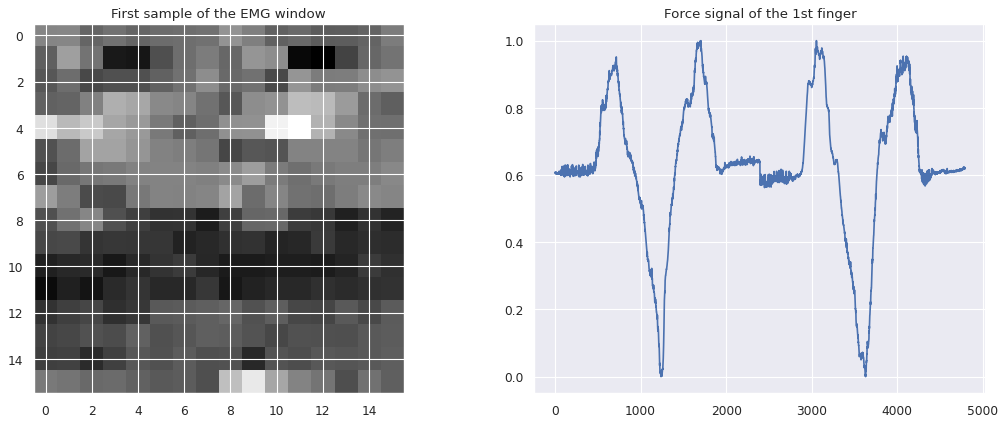

In [ ]:
# Get first window of EMG signal and force
emg_window, _ = next(iter(train_dataset_f1))
emg_window = emg_window[0]

force = []
for _, f in train_dataset_f1:
    force.append(f)
force = np.array(force)

# Plot EMG window
plt.figure(figsize=(16, 6), dpi=80)
plt.subplot(1, 2, 1)
plt.title("First sample of the EMG window")
plt.imshow(emg_window[:, :, 0], cmap='gray')

# Plot force
plt.subplot(1, 2, 2)
plt.title("Force signal of the 1st finger")
plt.plot(force[:, 0])
plt.show()

In [ ]:
# fw = []
# for force_weight in train_weights:
#     fw.append(force_weight)
# fw = np.array(fw)
#
# # Plot EMG window
# plt.figure(figsize=(16, 6), dpi=80)
# plt.title("Fore weights for the loss")
# plt.plot(fw)

### Validation dataset

In [ ]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample3.hea",
]

val_dataset_f1 = create_synced_datasets(
    path, emg_files_val_finger1, force_files_val_finger1
) # val_weights
val_dataset_f2 = create_synced_datasets(
    path, emg_files_val_finger2, force_files_val_finger2
)
val_dataset_f3 = create_synced_datasets(
    path, emg_files_val_finger3, force_files_val_finger3
)
val_dataset_f4 = create_synced_datasets(
    path, emg_files_val_finger4, force_files_val_finger4
)
val_dataset_f5 = create_synced_datasets(
    path, emg_files_val_finger5, force_files_val_finger5
)

### Test dataset

In [ ]:
emg_files_test_finger1 = [
    # "1dof_preprocess_finger1_sample1.hea",
    # "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_test_finger2 = [
    # "1dof_preprocess_finger2_sample1.hea",
    # "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_test_finger3 = [
    # "1dof_preprocess_finger3_sample1.hea",
    # "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_test_finger4 = [
    # "1dof_preprocess_finger4_sample1.hea",
    # "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_test_finger5 = [
    # "1dof_preprocess_finger5_sample1.hea",
    # "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_test_finger1 = [
    # "1dof_force_finger1_sample1.hea",
    # "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    # "1dof_force_finger2_sample1.hea",
    # "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_test_finger3 = [
    # "1dof_force_finger3_sample1.hea",
    # "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_test_finger4 = [
    # "1dof_force_finger4_sample1.hea",
    # "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
    # "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

test_dataset_f1 = create_synced_datasets(
    path2, emg_files_test_finger1, force_files_test_finger1
) # , _
test_dataset_f2 = create_synced_datasets(
    path2, emg_files_test_finger2, force_files_test_finger2
)
test_dataset_f3 = create_synced_datasets(
    path2, emg_files_test_finger3, force_files_test_finger3
)
test_dataset_f4 = create_synced_datasets(
    path2, emg_files_test_finger4, force_files_test_finger4
)
test_dataset_f5 = create_synced_datasets(
    path2, emg_files_test_finger5, force_files_test_finger5
)

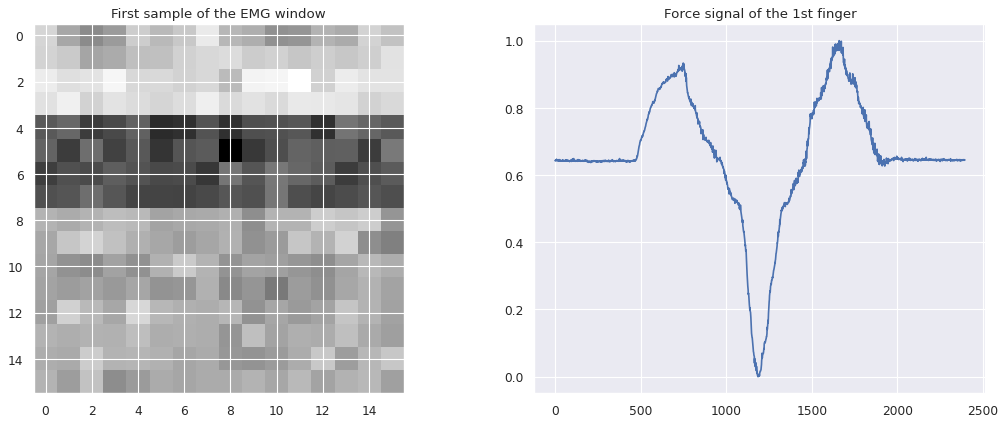

In [ ]:
# Get first window of EMG signal and force
emg_window, _ = next(iter(test_dataset_f1))
emg_window = emg_window[0]

force = []
for _, f in test_dataset_f1:
    force.append(f)
force=normalize(np.array(force), 0, 1)

# Plot EMG window
plt.figure(figsize=(16, 6), dpi=80)
plt.subplot(1, 2, 1)
plt.title("First sample of the EMG window")
plt.imshow(emg_window[:, :, 0], cmap='gray')

# Plot force
plt.subplot(1, 2, 2)
plt.title("Force signal of the 1st finger")
plt.plot(force[:, 0])
plt.show()

# Create the base model

In [ ]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
num_lstm_blocks = 1
input_shape = [100, 16, 16, 1] # train_dataset.element_spec[0].shape

estimator_f1 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
    num_lstm_blocks=num_lstm_blocks
)

estimator_f1.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d (DilatedC  (None, 100, 16, 16,  4912       ['input_1[0][0]']                
 onv2Plus1D)                     16)                                                              
                                                                                                  
 dilated_conv2_plus1d_1 (Dilate  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d[0][0]']   
 dConv2Plus1D)                   16)                                                          

In [ ]:
keras.utils.plot_model(estimator_f1, expand_nested=True, dpi=60, show_shapes=True)
# wavenet.plot_model()

: 

## Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_1/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_tensorboard/estimator_1/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=30,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

## Create the dataloader for training and validation

In [ ]:
batch_size = 8

dataset_train_f1 = train_dataset_f1.shuffle(buffer_size=len(train_dataset_f1)).batch(batch_size)
dataset_val_f1 = val_dataset_f1.batch(batch_size)

# Data augumentation

In [ ]:
#V variância do sinal de emg
var = tf.math.reduce_variance(train_dataset_f1[0])
var = 0.01 * var
desvio padrão do ruído gaussiano
std = tf.math.sqrt(var)

data_augmentation = tf.keras.Sequential([
  layers.GaussianNoise(stddev=var),
  AmplitudeScalingLayer(scale_range=(0.8, 1.2)),
  TimeShiftLayer(max_shift=0.1),
  PhaseRotationLayer(rotation_range=(-22/63, 22/63)), #pi/9
  layers.Dropout(0.2),
])

model = tf.keras.Sequential([
  data_augmentation,
  estimator_f1,
])

# Training

In [ ]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=optimizer, loss='mse')
# Fit data to model
history = model.fit(
    dataset_train_f1,
    epochs=100,
    validation_data=dataset_val_f1,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0364
Epoch 1: val_loss improved from inf to 0.15009, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet/
599/599 [==============================] - 127s 186ms/step - loss: 0.0364 - val_loss: 0.1501 - lr: 0.0010
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0180
Epoch 2: val_loss improved from 0.15009 to 0.03683, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet/
599/599 [==============================] - 111s 186ms/step - loss: 0.0180 - val_loss: 0.0368 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0129
Epoch 3: val_loss did not improve from 0.03683
599/599 [==============================] - 111s 185ms/step - loss: 0.0129 - val_loss: 0.0684 - lr: 0.0010
Epoch 4/100
599/599 [==============================] - ETA: 0s - loss: 0.0122
Epoch 4: val_loss improved from 0.03683 to 0.03111, savin

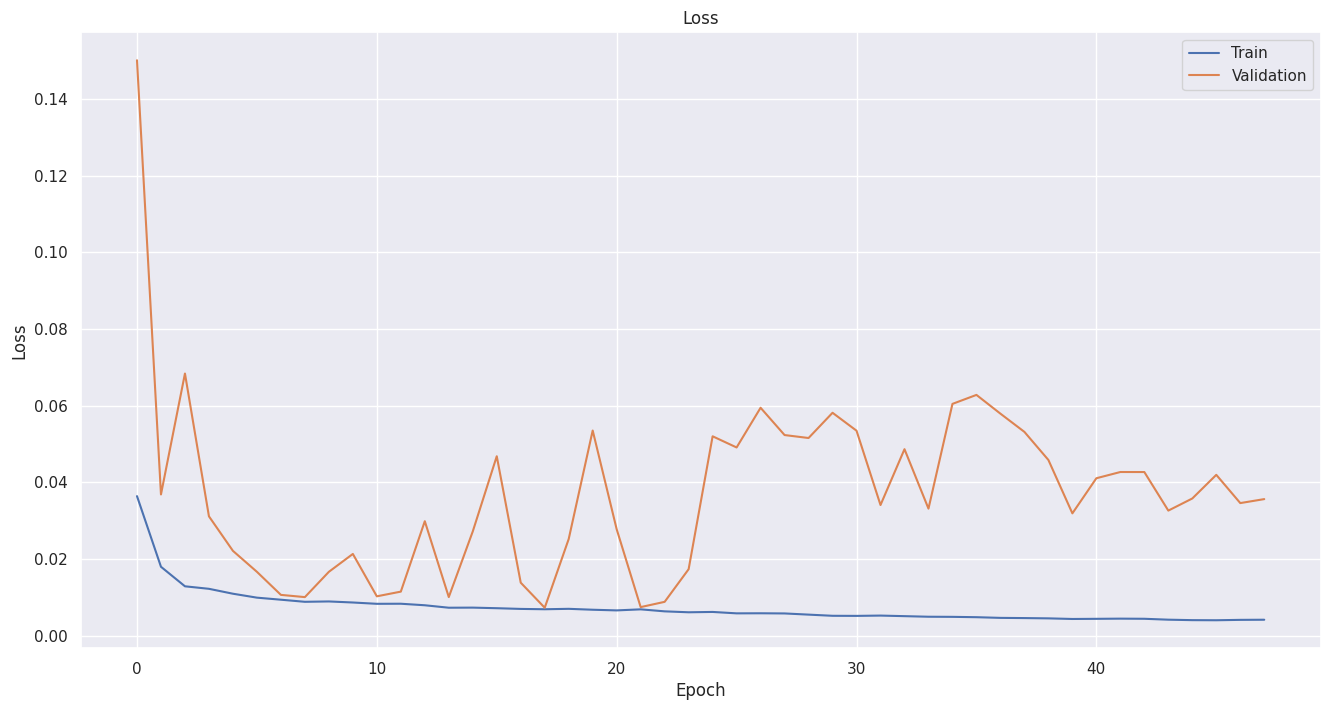

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

# Testing

In [ ]:
# Cria um objeto `tf.train.Checkpoint` com o modelo
checkpoint = tf.train.Checkpoint(model=wavenet)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint.restore(
    "gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_1/"
)

In [ ]:
emg_signal_windows, force_signal = [], []
for emg, f in train_dataset_f1.take(5000):
    emg_signal_windows.append(emg)
    force_signal.append(f)
emg_signal_windows = tf.constant(
    np.array(emg_signal_windows),
    dtype=tf.float32
)
force_signal = tf.constant(
    np.array(force_signal)
)[:,0]

print(emg_signal_windows.shape)
print(force_signal.shape)

(4790, 100, 16, 16, 1)
(4790,)


In [ ]:
predicted = wavenet.predict(emg_signal_windows)

150/150 [==============================] - 28s 177ms/step


In [ ]:
var_1 = tf.math.reduce_variance(emg_signal_windows)
var_1.numpy()

<tf.Tensor: shape=(), dtype=float32, numpy=0.009759559>

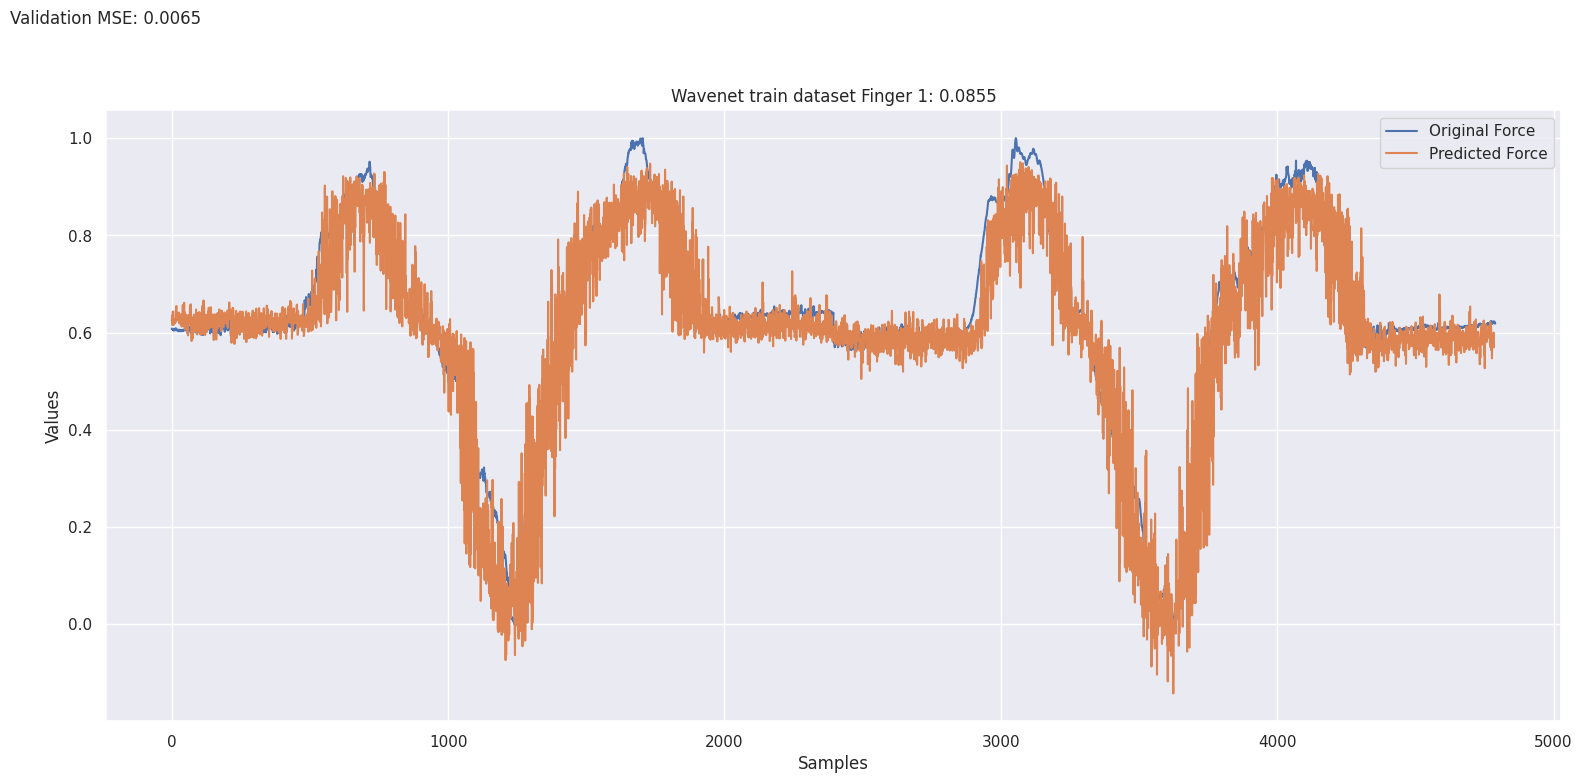

In [ ]:
# make_plot(predicted, force_signal, "Wavenet:")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 8)) #
mse_ = calc_mse(predicted, force_signal)
title = f"Wavenet train dataset Finger 1: {mse_:.4f}"
for i in range(1):
    mse = calc_mse(predicted[:,0], force_signal)
    ax.plot(force_signal, label='Original Force')
    ax.plot(predicted[:,0][5:], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
           ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {0+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")
plt.title(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f1:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = wavenet.predict(emg_signal_windows_test)

In [53]:
errors_f1 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f1)}')
print(f'variance error: {tf.math.reduce_variance(errors_f1)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.06316309422254562
variance error: 0.0031487196683883667
r^2: 0.7662891455549933


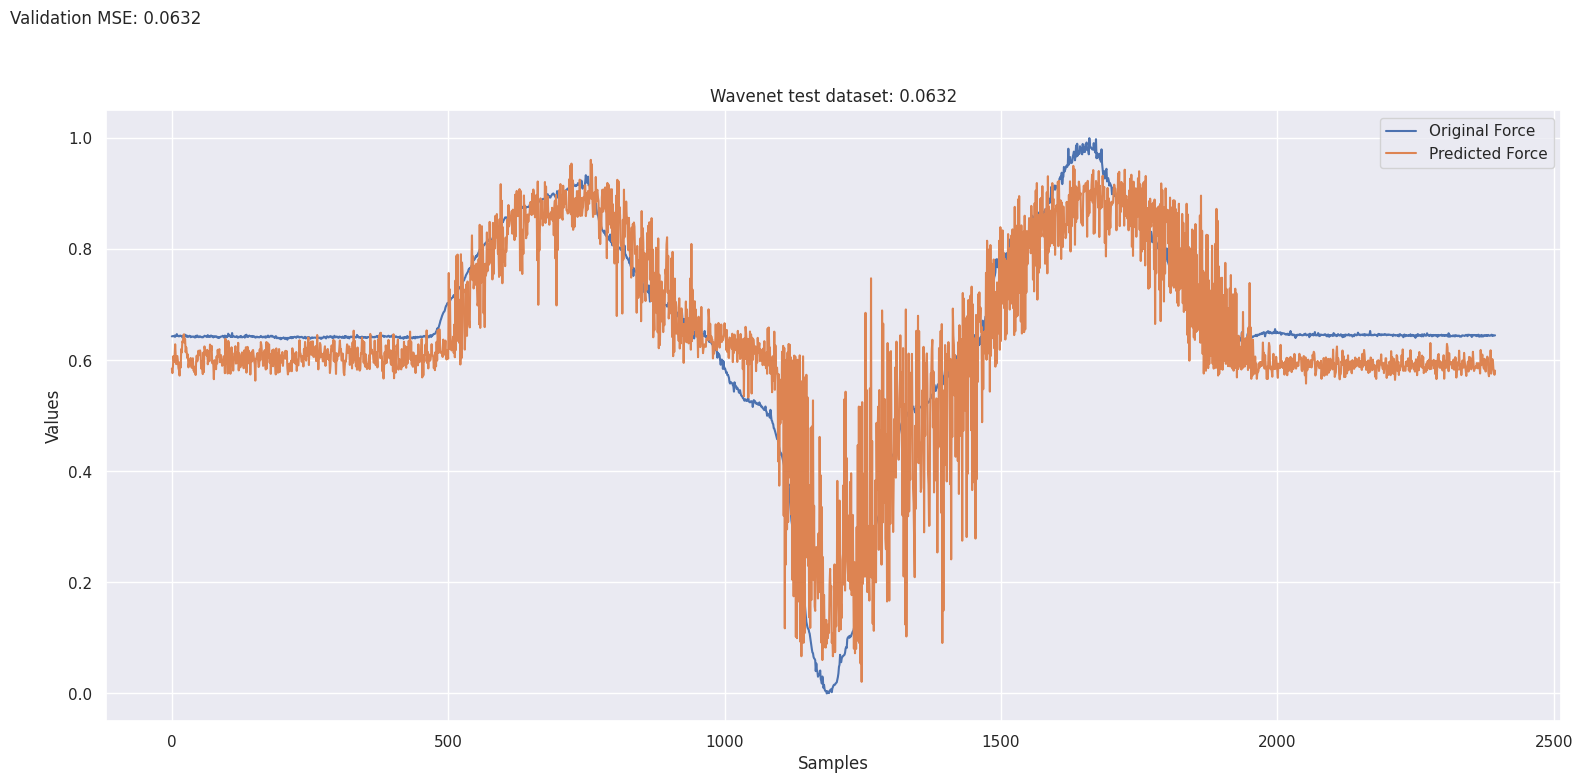

In [54]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)
fig, ax = plt.subplots(figsize=(16, 8)) # nrows=5, ncols=1,
mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"
for i in range(1):
    mse = calc_mse(predicted_test, outputs)
    ax.plot(outputs, label='Original Force')
    ax.plot(predicted_test[:,i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
        ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")
plt.title(title)
plt.tight_layout()
plt.legend()
plt.show()

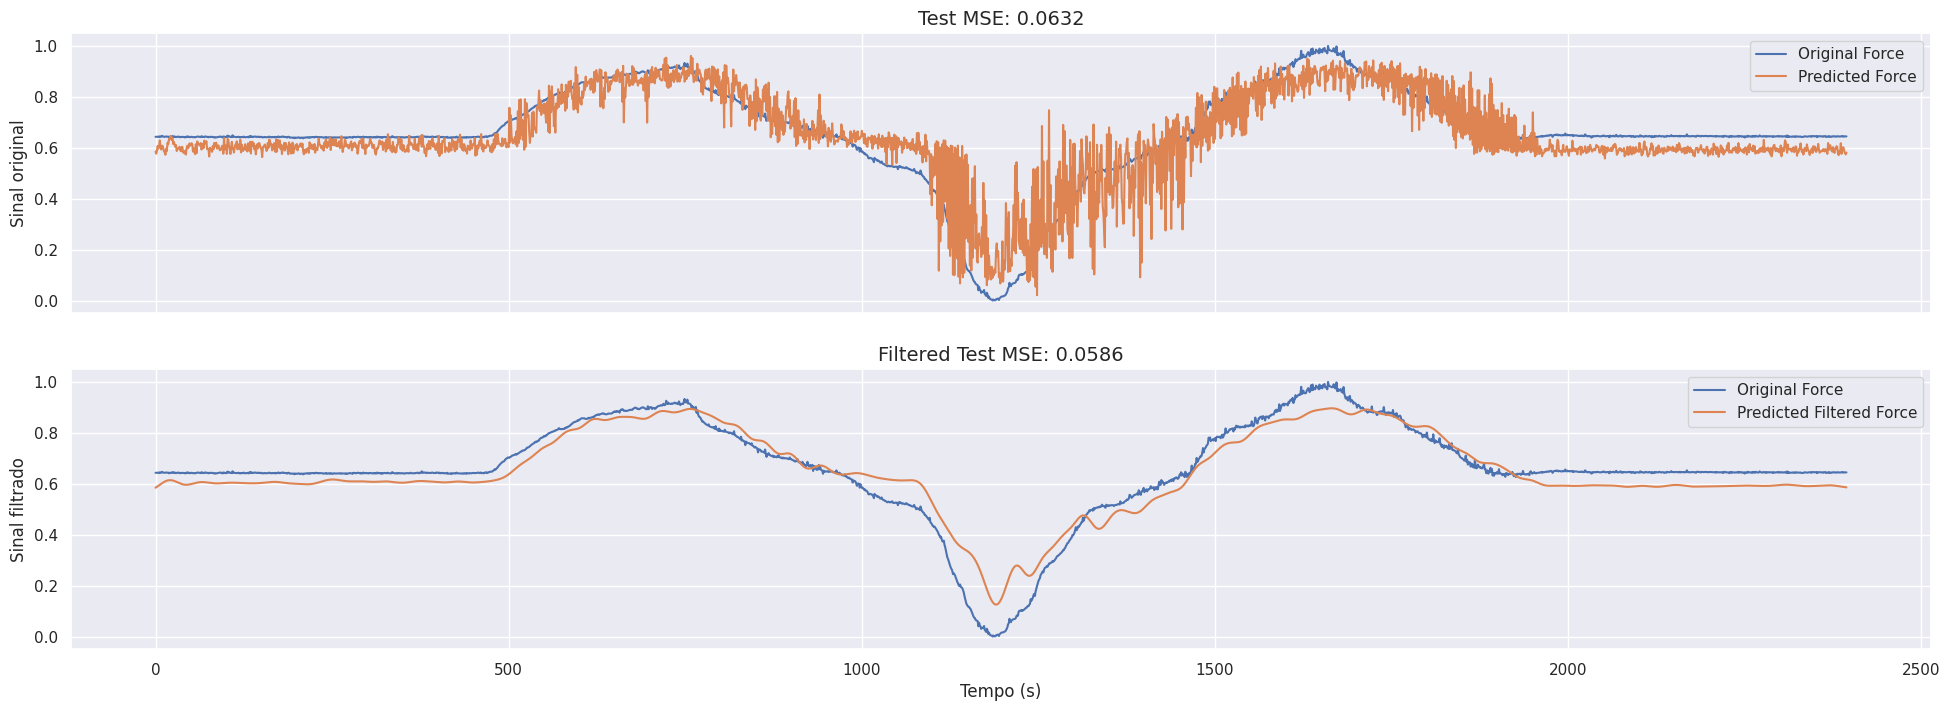

In [55]:
from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

In [56]:
print(f'r^2: {r2(y, outputs)}')

r^2: 0.8491359243560428


# Other fingers

## Finger 2

In [57]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_2/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Colab_Notebooks/estimator/logs/logs/model_1DoF_tensorboard/wavenet_2/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [59]:
dataset_train_f2 = train_dataset_f2.shuffle(buffer_size=len(train_dataset_f2)).batch(batch_size)
dataset_val_f2 = val_dataset_f2.batch(batch_size)

In [60]:
# Carregue o modelo pré-treinado
pretrained_model = wavenet

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f2 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
estimator_f2 = wavenet

model_f2 = tf.keras.Sequential([
  # data_augmentation,
  estimator_f2,
])

# Compile o modelo
model_f2.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f2.fit(
    dataset_train_f2,
    validation_data=dataset_val_f2,
    epochs=10,
    callbacks=callback,
)

598/599 [============================>.] - ETA: 0s - loss: 0.0331
Epoch 1: val_loss improved from inf to 0.04482, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet_f2/
599/599 [==============================] - 42s 69ms/step - loss: 0.0330 - val_loss: 0.0448 - lr: 0.0010


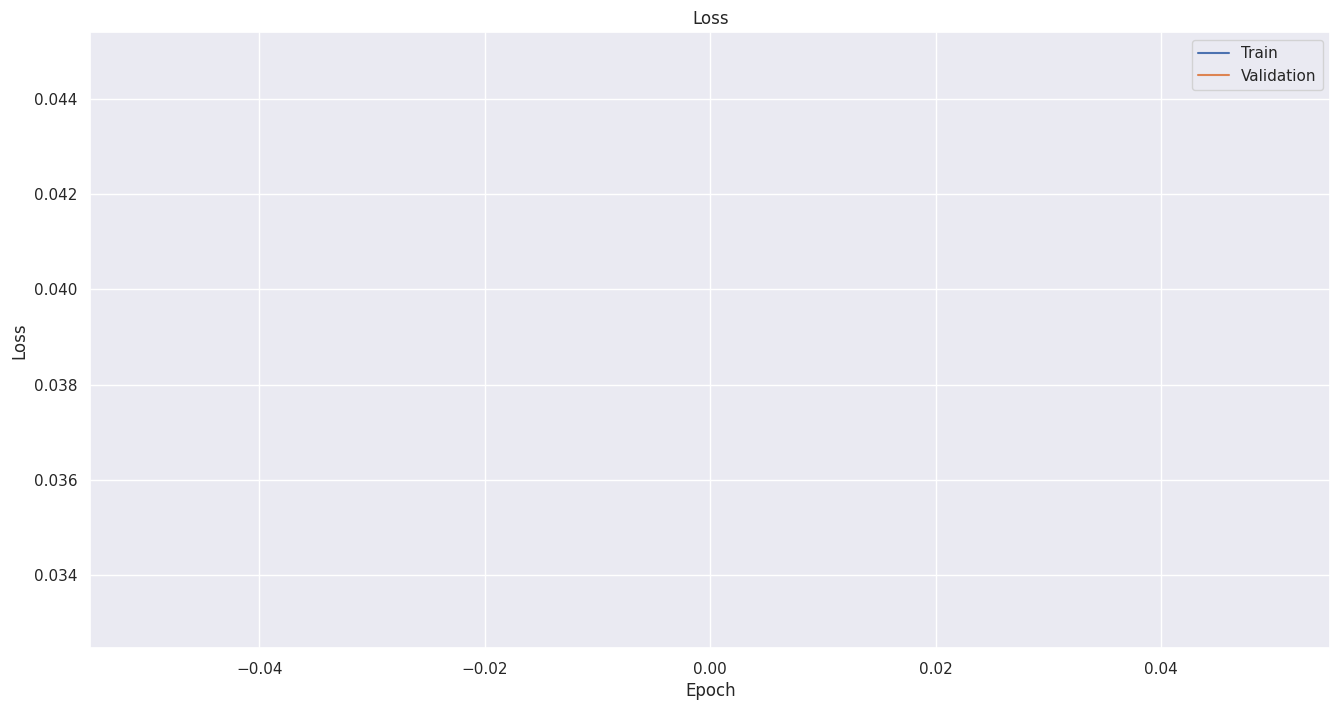

In [61]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [62]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [63]:
predicted_test = estimator_f2.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 177ms/step


In [64]:
errors_f2 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f2)}')
print(f'variance error: {tf.math.reduce_variance(errors_f2)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.07240256667137146
variance error: 0.0009951636893674731
r^2: -13458.704116723682


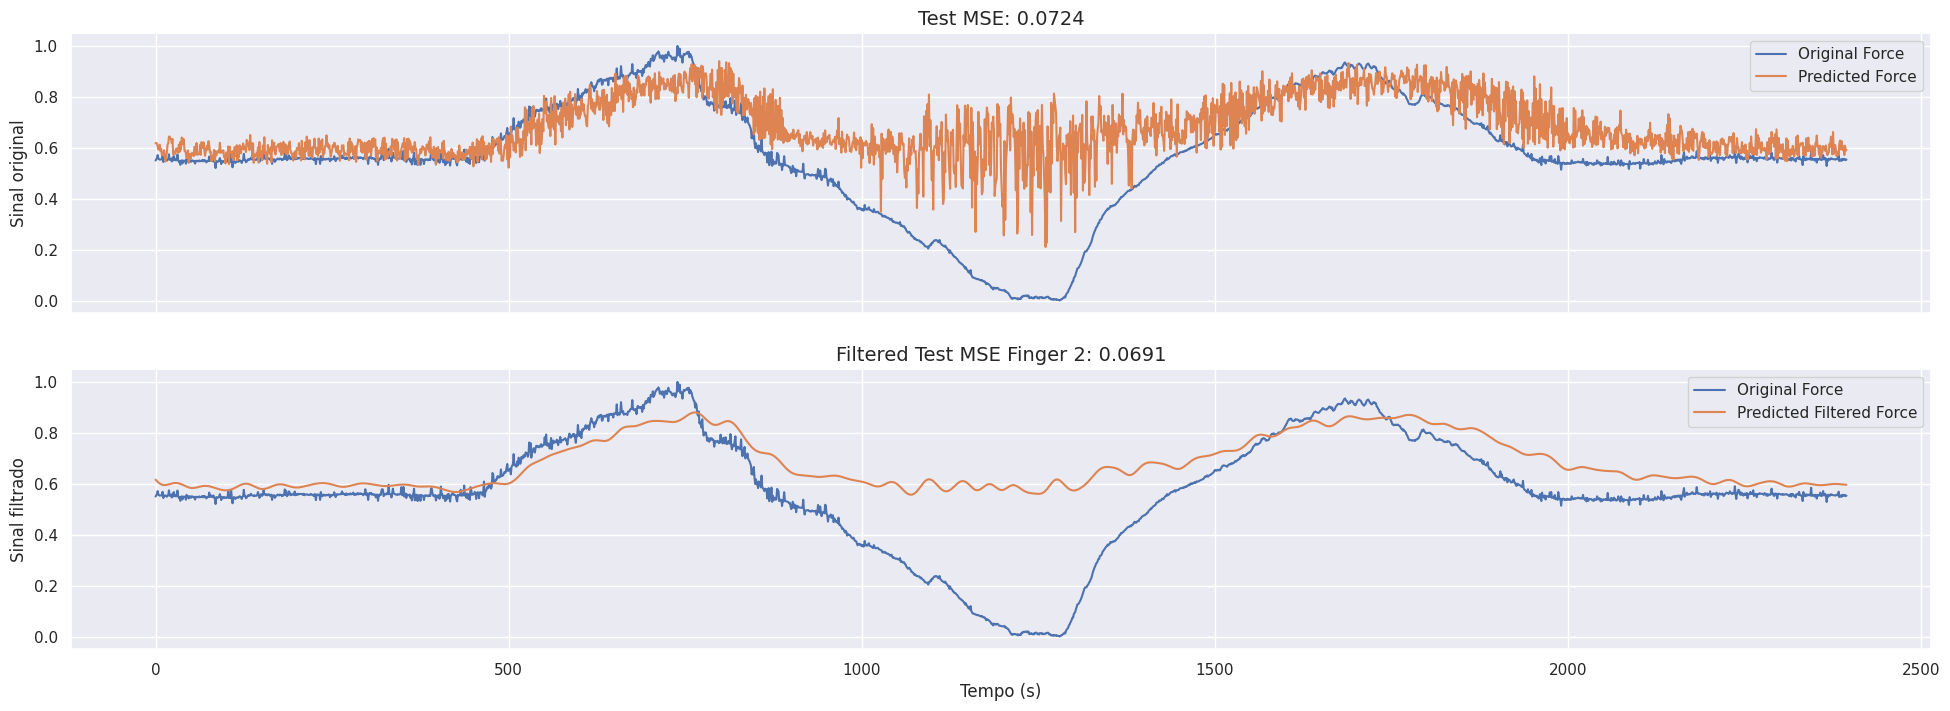

In [65]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 2: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 3

In [66]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_3/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_tensorboard/estimator_3/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [67]:
dataset_train_f3 = train_dataset_f3.shuffle(buffer_size=len(train_dataset_f3)).batch(batch_size)
dataset_val_f3 = val_dataset_f3.batch(batch_size)

In [68]:
# Carregue o modelo pré-treinado
pretrained_model = estimator

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f3 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
estimator_f3 = estimator

model_f3 = tf.keras.Sequential([
  # data_augmentation,
  wavenet_f3,
])

# Compile o modelo
model_f3.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f3.fit(
    dataset_train_f3,
    validation_data=dataset_val_f3,
    epochs=10,
    callbacks=callback,
)

598/599 [============================>.] - ETA: 0s - loss: 0.0333
Epoch 1: val_loss improved from inf to 0.03898, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet_f3/
599/599 [==============================] - 44s 72ms/step - loss: 0.0332 - val_loss: 0.0390 - lr: 0.0010


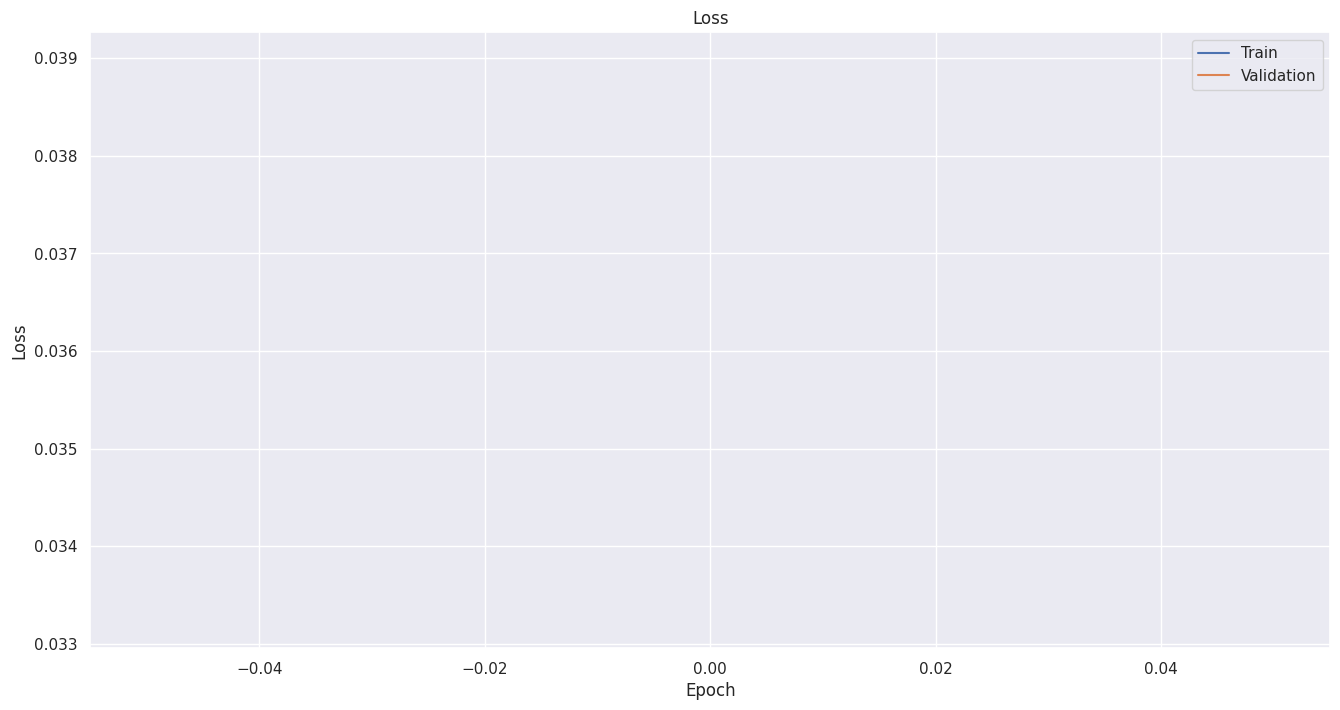

In [69]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [70]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [71]:
predicted_test = estimator_f3.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 177ms/step


In [72]:
errors_f3 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f3)}')
print(f'variance error: {tf.math.reduce_variance(errors_f3)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.07240256667137146
variance error: 0.0009951636893674731
r^2: -13458.704116723682


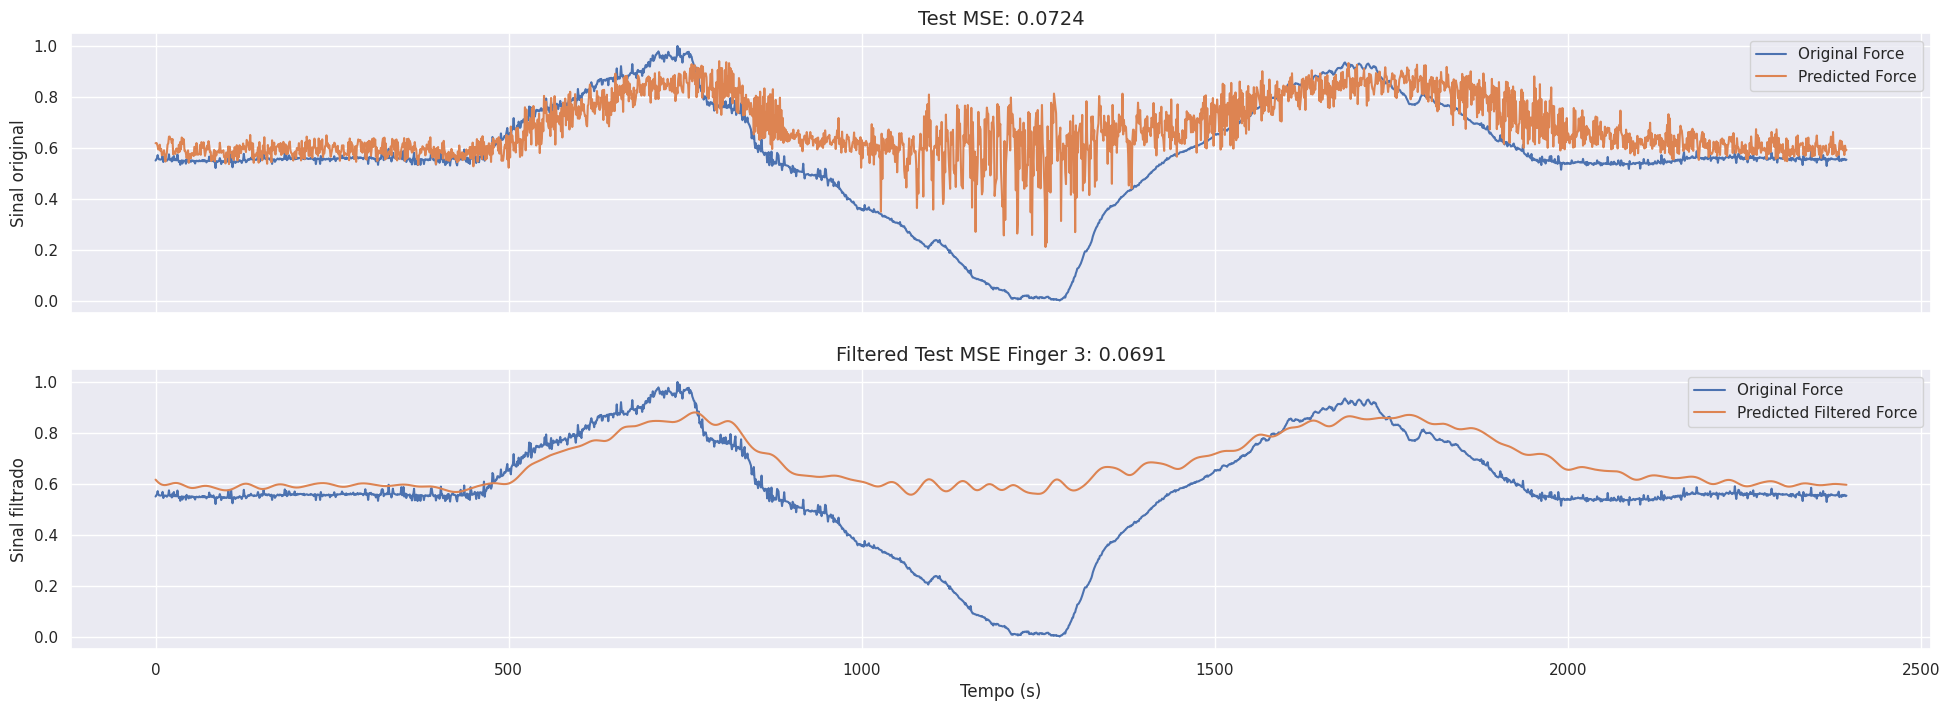

In [73]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 3: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 4

In [74]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_4/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_tensorboard/estimator_4/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [75]:
dataset_train_f4 = train_dataset_f4.shuffle(buffer_size=len(train_dataset_f4)).batch(batch_size)
dataset_val_f4 = val_dataset_f4.batch(batch_size)

In [76]:
# Carregue o modelo pré-treinado
pretrained_model = wavenet

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f4 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
estimator_f4 = wavenet

model_f4 = tf.keras.Sequential([
  # data_augmentation,
  estimator_f4,
])

# Compile o modelo
model_f4.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f3.fit(
    dataset_train_f4,
    validation_data=dataset_val_f4,
    epochs=10,
    callbacks=callback,
)

598/599 [============================>.] - ETA: 0s - loss: 0.0523
Epoch 1: val_loss improved from inf to 0.04199, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet_f4/
599/599 [==============================] - 42s 70ms/step - loss: 0.0523 - val_loss: 0.0420 - lr: 0.0010


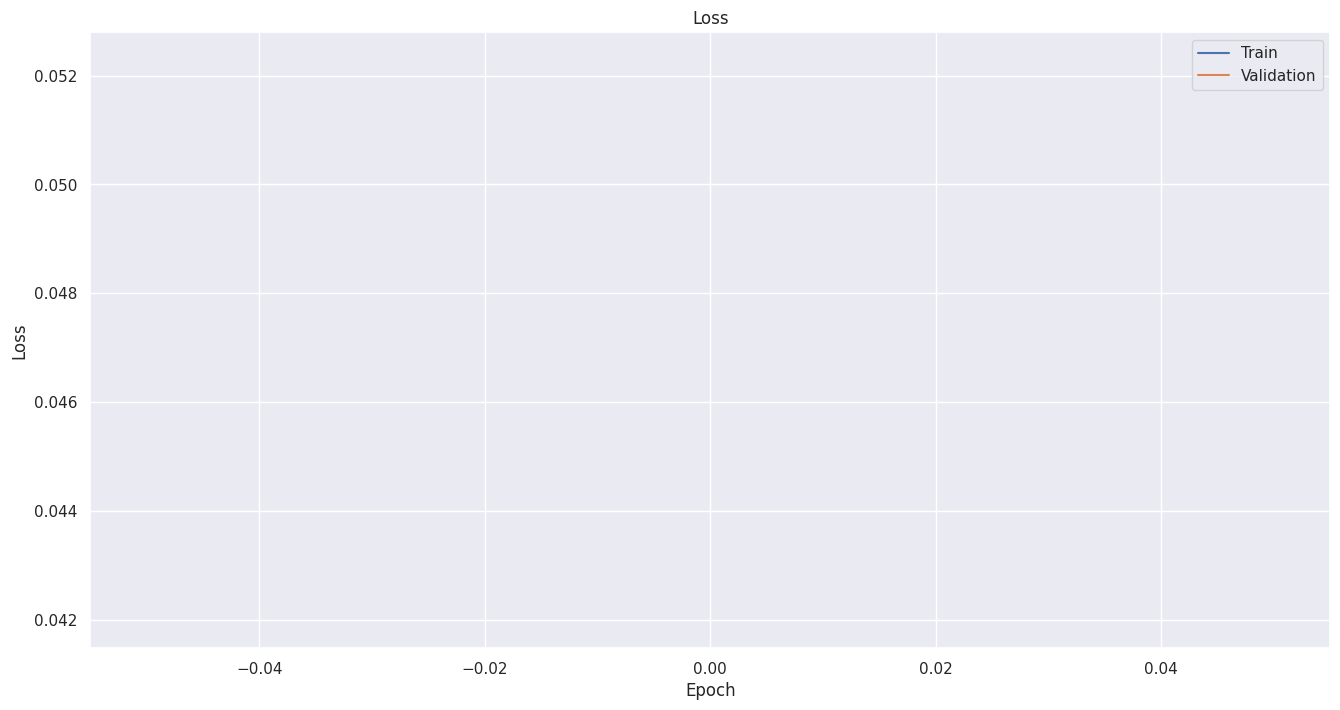

In [77]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [78]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f4:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [79]:
predicted_test = estimator_f4.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 178ms/step


In [80]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.0421377494931221
variance error: 0.0001206227025249973
r^2: -9270.380455510724


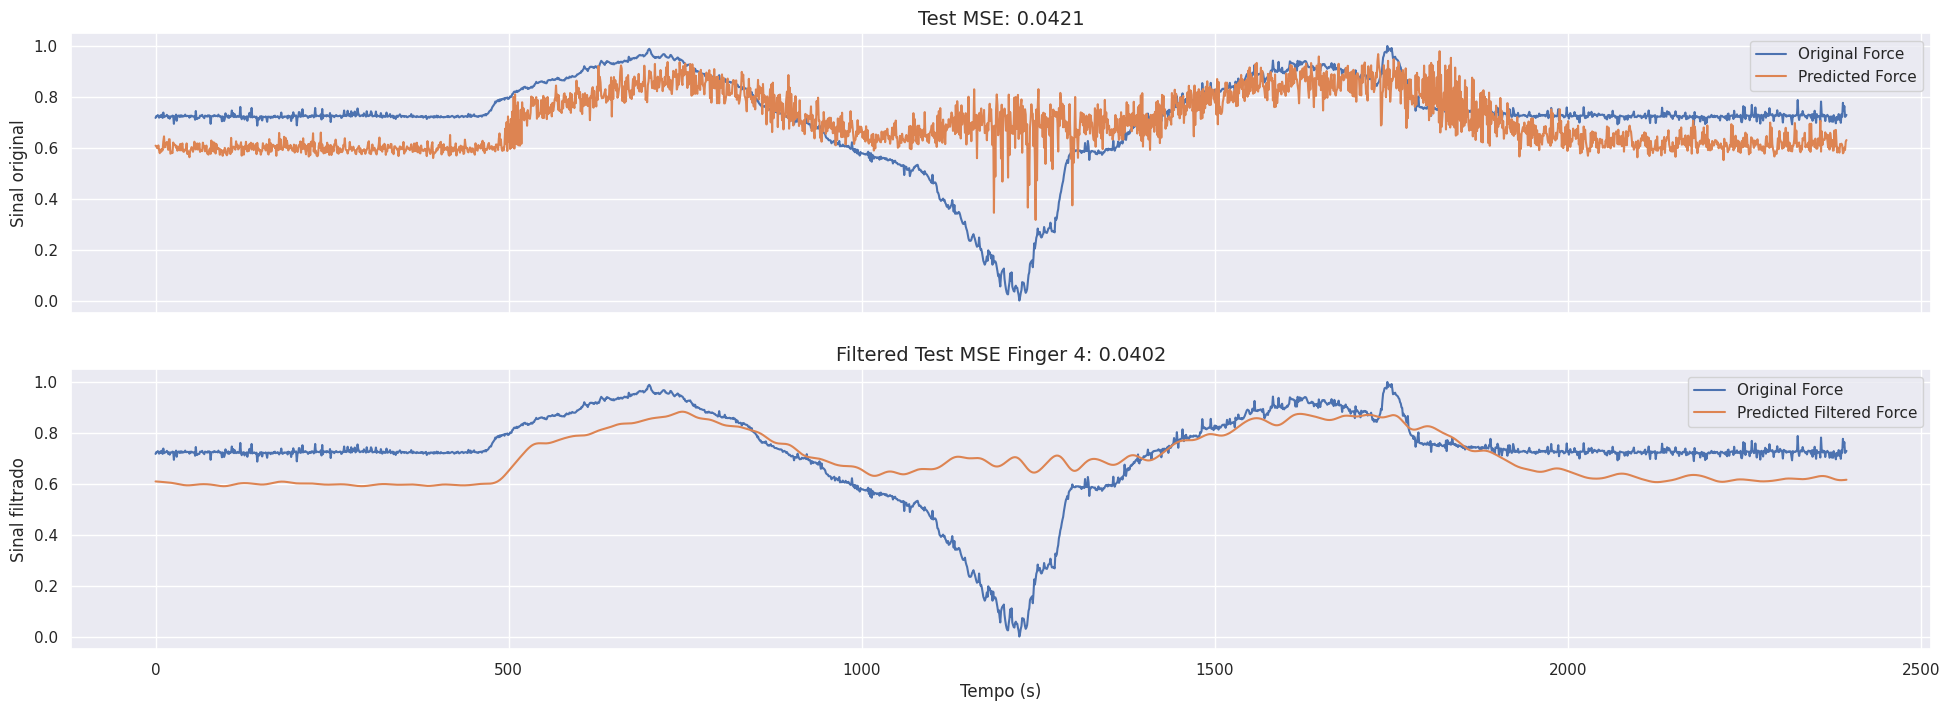

In [81]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 4: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

## Finger 5

In [82]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_checkpoint/estimator_5/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Colab_Notebooks/estimator/logs/model_1DoF_tensorboard/estimator_5/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=10,
        min_lr=1e-8,
    ),
]

In [83]:
dataset_train_f5 = train_dataset_f5.shuffle(buffer_size=len(train_dataset_f5)).batch(batch_size)
dataset_val_f5 = val_dataset_f5.batch(batch_size)

In [84]:
# Carregue o modelo pré-treinado
pretrained_model = wavenet

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
# wavenet_f5 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)
estimator_f5 = wavenet

model_f5 = tf.keras.Sequential([
  # data_augmentation,
  estimator_f5,
])

# Compile o modelo
model_f5.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f5.fit(
    dataset_train_f5,
    validation_data=dataset_val_f5,
    epochs=10,
    callbacks=callback,
)

598/599 [============================>.] - ETA: 0s - loss: 0.0441
Epoch 1: val_loss improved from inf to 0.05208, saving model to gdrive/MyDrive/Colab_Notebooks/logs/model_1DoF_checkpoint/wavenet_f5/
599/599 [==============================] - 44s 71ms/step - loss: 0.0441 - val_loss: 0.0521 - lr: 0.0010


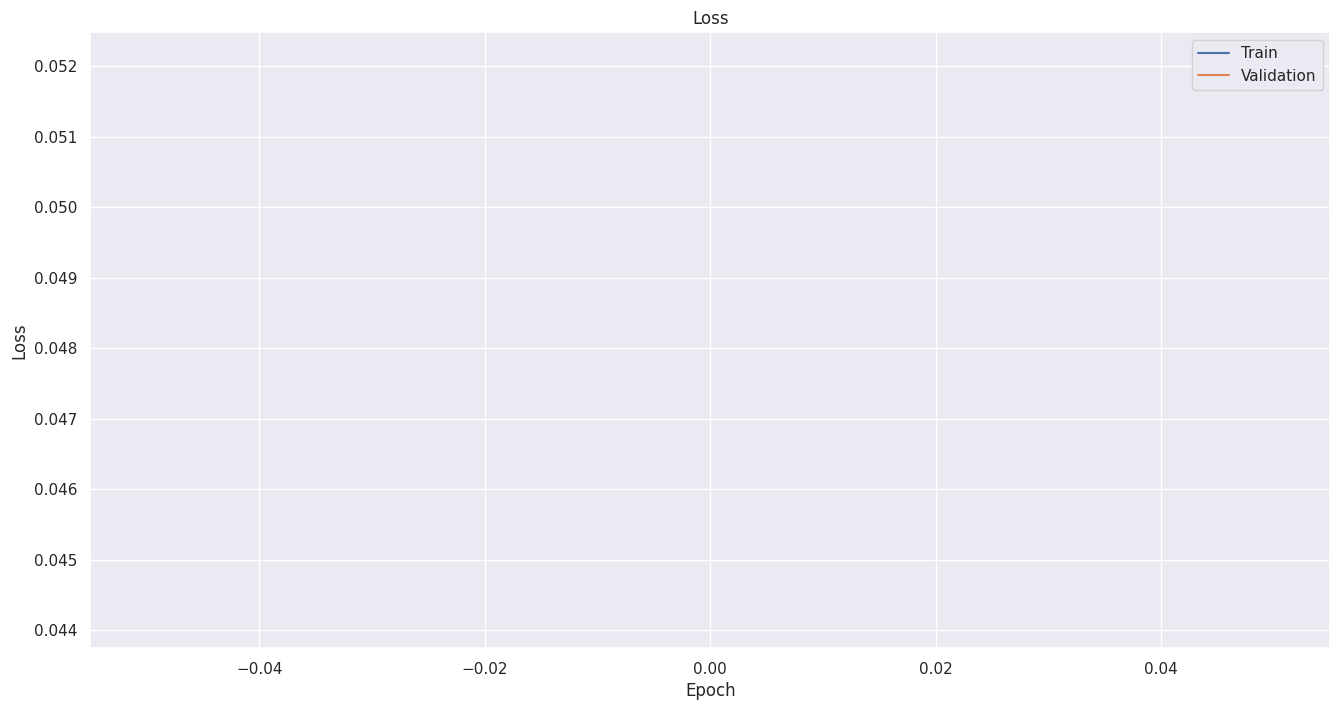

In [85]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [86]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f2:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [87]:
predicted_test = estimator_f5.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 178ms/step


In [88]:
errors_f5 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f5)}')
print(f'variance error: {tf.math.reduce_variance(errors_f5)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.07240256667137146
variance error: 0.0009951636893674731
r^2: -13458.704116723682


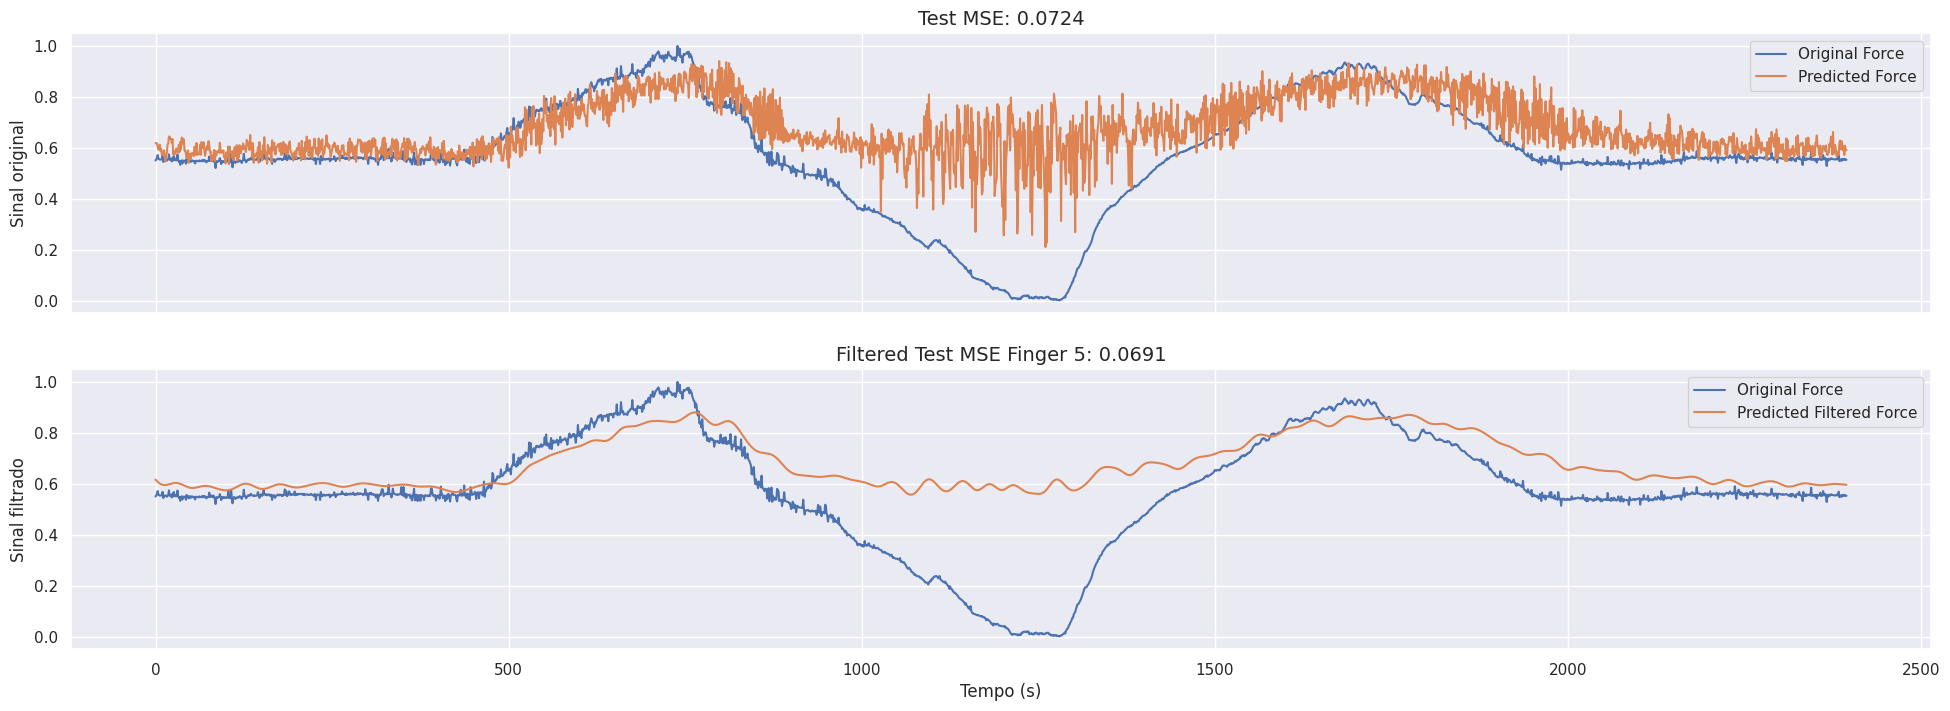

In [89]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE Finger 5: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

In [92]:
print(f'r^2: {r2(y, outputs)}')

r^2: -2.7825933199768045


# Mean and variance of the error

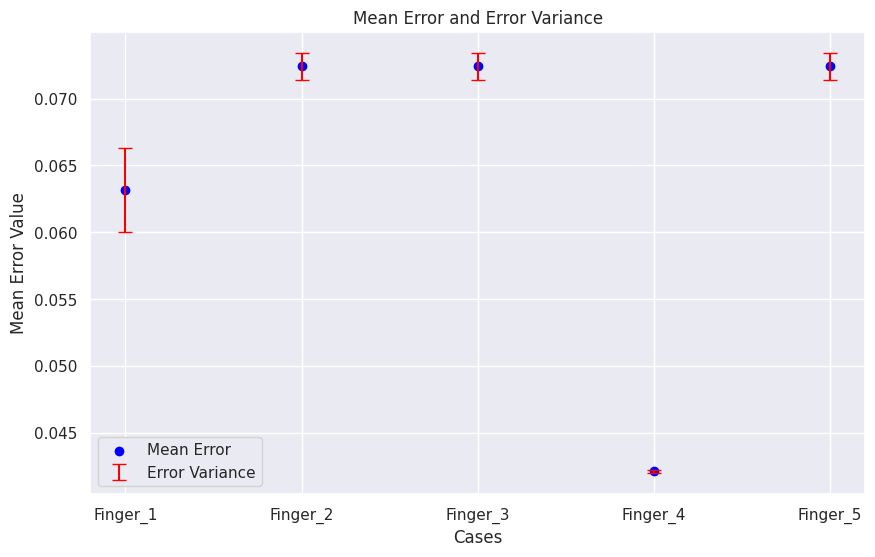

In [90]:
# Dados dos erros e variâncias
errors = [
    tf.reduce_mean(errors_f1),
    tf.reduce_mean(errors_f2),
    tf.reduce_mean(errors_f3),
    tf.reduce_mean(errors_f4),
    tf.reduce_mean(errors_f5),
]
variances = [
    tf.math.reduce_variance(errors_f1),
    tf.math.reduce_variance(errors_f2),
    tf.math.reduce_variance(errors_f3),
    tf.math.reduce_variance(errors_f4),
    tf.math.reduce_variance(errors_f5),
]

# Create the plot
plt.figure(figsize=(10, 6))  # Define the figure size

# Plot error points
plt.scatter(range(1, 6), errors, color='blue', label='Mean Error')

# Plot variance bars
plt.errorbar(range(1, 6), errors, yerr=variances, fmt='none', ecolor='red', capsize=5, label='Error Variance')

# Plot settings
plt.xlabel('Cases')
plt.ylabel('Mean Error Value')
plt.title('Mean Error and Error Variance')
plt.legend()

# Define X-axis labels
names = [f'Finger_{i}' for i in range(1, 6)]
plt.xticks(range(1, 6), names)

# Show the plot
plt.show()